# GVH Diagonal Cubic — CHH-ROOT22 Cross-System Invariant Universality Gate — FAST

**Objective:** examine whether the historical exact algebraic number $\sqrt{22}$ yields a **non-arbitrary, predictive, dimensionless** quantity across different astronomical host systems. This is **not** a claim of a new constant.

**Scientific decision rule (declared before computing the catalogue):** compare fixed, unadjusted hypotheses $K=1$ (two-body Newton/Kepler reference), $K=\sqrt{22}$, $K=1/\sqrt{22}$, $K=(\sqrt{22}-2)/9$ and $K=(\sqrt{22}-4)/9$ with a single adjusted coefficient trained only on the Sun-orbit subset, evaluated on other hosts. Allowing a freely chosen coefficient in each system is explicitly **non-identifiable** and cannot validate $\sqrt{22}$.

**Evidence class:** archival algebra and published *catalogue-derived orbital parameters*, not raw independent measurements. The analysed Kepler ratio is tied to the dynamical fitting of the catalogue, so even $K\approx1$ is a consistency check, not a novel experimental confirmation. Source table values are frozen into this offline notebook; no live download, hidden catalogue updates, or post-hoc selection.

**Preserve our architecture:** (1) GVH / CHH hypothesis; (2) established physics; (3) minimal numerical audit; (4) scientific verdict. CHH is a **composition framework**. All derivatives, Kepler equations, and cross-system statistics here are **auxiliary established physics and tests**, never equations derived by CHH composition.

## Level 1 — GVH: historical provenance and exact definitions

Prior archival audit `GVH_G284_ROOT22_Provenance_Factorization_and_Universality_Gate_FAST` identified a **single connected G284 branch**:

\[
\lambda=\frac{\sqrt{22}-2}{9},\quad c_2=\frac{\sqrt{22}-4}{9},\quad \lambda-c_2=\frac29.
\]

At the frozen point $(c_{13},\zeta_C,c_2,c_{14})=(0,1,(\sqrt{22}-4)/9,0)$, the previous reduced quadratic audit did **not** pass its kinetic health test; a negative dispersion direction was also found on the frozen slice. Do **not** extrapolate these root values to other GVH branches or to different objects.

Tested candidate embeddings of the same numerical factor into a *separate, explicitly chosen* orbital dimensionless statistic must be treated as **new phenomenological hypotheses** (not derived from the G284 dispersion law).

In [1]:
import json, hashlib, math
from pathlib import Path
import numpy as np, pandas as pd, sympy as sp
from matplotlib import pyplot as plt

STEM='GVH_CHH_Root22_Cross_System_Invariant_Universality_Gate_FAST'
OUT=Path('/mnt/data') if Path('/mnt/data').exists() else Path.cwd()
checks={}
def check(name, condition):
    if name in checks: raise RuntimeError('Repeated check name: '+name)
    checks[name]=bool(condition)
    assert checks[name], name

s22=sp.sqrt(22)
c2=(s22-4)/9
lam=(s22-2)/9
check('historical_c2_polynomial',sp.simplify(27*c2**2+24*c2-2)==0)
check('historical_dispersion_polynomial',sp.simplify(9*lam**2+4*lam-2)==0)
check('historical_lambda_minus_c2',sp.simplify(lam-c2-sp.Rational(2,9))==0)
check('historical_c2_unhealthy_on_reduced_slice',bool(c2>=-sp.Rational(2,3)))
check('historical_bad_mode_sign',bool((2-s22)/9<0))
print('sqrt22=',float(s22),'lambda=',float(lam),'c2=',float(c2))

upstream_path=OUT/'GVH_G284_ROOT22_Provenance_Factorization_and_Universality_Gate_FAST_results.json'
if upstream_path.exists():
    upstream=json.loads(upstream_path.read_text())
    check('upstream_archival_cert_16_pass',upstream.get('pass_count')==16)
    check('upstream_not_universal',upstream.get('flags',{}).get('universal_root22_tested') is False)
    provenance={'upstream_available':True,'upstream_file':upstream_path.name,'upstream_sha256':hashlib.sha256(upstream_path.read_bytes()).hexdigest()}
else:
    # The numerical audit is portable, with explicit provenance qualification.
    provenance={'upstream_available':False,'upstream_file':upstream_path.name,'upstream_sha256':None}
print('Archive source available?',provenance['upstream_available'])

sqrt22= 4.69041575982343 lambda= 0.2989350844248255 c2= 0.07671286220260329
Archive source available? True


## Level 2 — Physics established: dimensionless reference and sourced data

For an approximate two-body orbit, with semimajor axis $a$ and sidereal period $P$, define the **dimensionless** consistency ratio

\[
\boxed{K_{\rm orb}=\frac{4\pi^2 a^3}{\mu_{\rm host}P^2},\qquad \mu_{\rm host}=GM_{\rm host}.}
\]

The reference is $K=1$ under Kepler/Newton hypotheses. For non-isolated many-body systems, non-Keplerian perturbations, rounded quantities, different fit epochs, or an approximate host-system $GM$, it need not equal 1 exactly. The table's $a,P,GM$ are already model-dependent estimated catalogue values, not independent raw observations. **No formal observational error bars** are provided for this cross-table harmonization; therefore do not assign statistical significance to small deviations.

**Sources and frozen values:**

* Sun planets: NASA NSSDCA **individual planetary fact sheets**, semimajor axes in $10^6$ km and **sidereal**, not tropical, periods in days. Solar source URLs are in `sources` below. Do **not** use the rounded main-table tropical orbital periods.
* Moon/Mars/Jupiter/Saturn/Neptune satellites: NASA NSSDCA Jovian satellite fact sheet and/or JPL SSD mean satellite elements, which use non-identical reference frames/epochs/mean definitions. Planetary and satellite ephemeris-derived elements should not be considered independently measured $a$ and $P$.
* Host gravitational parameters: JPL SSD astrodynamic parameters (DE440), converted to km³/s². The JPL 'system' GM may include satellites, so treating it as an isolated primary is an approximation.

**Hold-out design:** train a possible single auxiliary scale **only on 8 Sun orbits**; report predictions on 12 satellite orbits around Earth, Mars, Jupiter, Saturn and Neptune. This is a *host-level descriptive holdout*, **not prospective blindness**.

In [2]:
sources={
 'jpl_gm':'https://ssd.jpl.nasa.gov/astro_par.html',
 'jpl_sat':'https://ssd.jpl.nasa.gov/sats/elem/sep.html',
 'nasa_jovian':'https://nssdc.gsfc.nasa.gov/planetary/factsheet/joviansatfact.html',
 'nasa_mercury':'https://nssdc.gsfc.nasa.gov/planetary/factsheet/mercuryfact.html',
 'nasa_venus':'https://nssdc.gsfc.nasa.gov/planetary/factsheet/venusfact.html',
 'nasa_earth':'https://nssdc.gsfc.nasa.gov/planetary/factsheet/earthfact.html',
 'nasa_mars':'https://nssdc.gsfc.nasa.gov/planetary/factsheet/marsfact.html',
 'nasa_jupiter':'https://nssdc.gsfc.nasa.gov/planetary/factsheet/jupiterfact.html',
 'nasa_saturn':'https://nssdc.gsfc.nasa.gov/planetary/factsheet/saturnfact.html',
 'nasa_uranus':'https://nssdc.gsfc.nasa.gov/planetary/factsheet/uranusfact.html',
 'nasa_neptune':'https://nssdc.gsfc.nasa.gov/planetary/factsheet/neptunefact.html',
}
mu_km3_s2={
 'Sun':132712440041.279419, 'Earth':398600.435507,
 'Mars':42828.375816,'Jupiter':126712764.1,
 'Saturn':37940584.8418,'Neptune':6836527.10058,
}
# host, body, a[km], P[sidereal d], orbit source ID
frozen_records=[
 ('Sun','Mercury',57.909e6,87.969,'nasa_mercury'),
 ('Sun','Venus',108.210e6,224.701,'nasa_venus'),
 ('Sun','Earth',149.598e6,365.256,'nasa_earth'),
 ('Sun','Mars',227.956e6,686.980,'nasa_mars'),
 ('Sun','Jupiter',778.479e6,4332.589,'nasa_jupiter'),
 ('Sun','Saturn',1432.041e6,10755.699,'nasa_saturn'),
 ('Sun','Uranus',2867.043e6,30685.400,'nasa_uranus'),
 ('Sun','Neptune',4514.953e6,60189.018,'nasa_neptune'),
 ('Earth','Moon',384400,27.322,'jpl_sat'),
 ('Mars','Phobos',9375,0.3187,'jpl_sat'),
 ('Mars','Deimos',23457,1.2625,'jpl_sat'),
 ('Jupiter','Io',421800,1.769138,'nasa_jovian'),
 ('Jupiter','Europa',671100,3.551181,'nasa_jovian'),
 ('Jupiter','Ganymede',1070400,7.154553,'nasa_jovian'),
 ('Jupiter','Callisto',1882700,16.689017,'nasa_jovian'),
 ('Saturn','Enceladus',238400,1.370218,'jpl_sat'),
 ('Saturn','Dione',377700,2.736916,'jpl_sat'),
 ('Saturn','Rhea',527200,4.517503,'jpl_sat'),
 ('Saturn','Titan',1221900,15.945448,'jpl_sat'),
 ('Neptune','Triton',354800,5.8792,'jpl_sat'),
]
cols=['host','body','a_km','P_days','source_id']
df=pd.DataFrame(frozen_records,columns=cols)
df['gm_host_km3_s2']=df.host.map(mu_km3_s2)
df['source_url']=df.source_id.map(sources)
df['partition']=np.where(df.host=='Sun','training_Sun','heldout_nonSun')
check('twenty_frozen_orbits',len(df)==20)
check('six_distinct_hosts',df.host.nunique()==6)
check('eight_training_and_twelve_heldout',((df.partition=='training_Sun').sum(),(df.partition=='heldout_nonSun').sum())==(8,12))
check('five_distinct_heldout_hosts',df[df.partition=='heldout_nonSun'].host.nunique()==5)
check('unique_host_body_pair',not df.duplicated(['host','body']).any())
check('all_orbit_sources_explicit',bool(df.source_url.notna().all()))
check('all_parameters_finite_positive',bool(np.isfinite(df[['a_km','P_days','gm_host_km3_s2']].to_numpy()).all() and (df[['a_km','P_days','gm_host_km3_s2']].to_numpy()>0).all()))
check('source_urls_are_verified_domains',all(url.startswith(('https://ssd.jpl.nasa.gov/','https://nssdc.gsfc.nasa.gov/')) for url in sources.values()))
print(df[['host','body','a_km','P_days','partition']].to_string(index=False))

   host      body         a_km       P_days      partition
    Sun   Mercury   57909000.0    87.969000   training_Sun
    Sun     Venus  108210000.0   224.701000   training_Sun
    Sun     Earth  149598000.0   365.256000   training_Sun
    Sun      Mars  227956000.0   686.980000   training_Sun
    Sun   Jupiter  778479000.0  4332.589000   training_Sun
    Sun    Saturn 1432041000.0 10755.699000   training_Sun
    Sun    Uranus 2867043000.0 30685.400000   training_Sun
    Sun   Neptune 4514953000.0 60189.018000   training_Sun
  Earth      Moon     384400.0    27.322000 heldout_nonSun
   Mars    Phobos       9375.0     0.318700 heldout_nonSun
   Mars    Deimos      23457.0     1.262500 heldout_nonSun
Jupiter        Io     421800.0     1.769138 heldout_nonSun
Jupiter    Europa     671100.0     3.551181 heldout_nonSun
Jupiter  Ganymede    1070400.0     7.154553 heldout_nonSun
Jupiter  Callisto    1882700.0    16.689017 heldout_nonSun
 Saturn Enceladus     238400.0     1.370218 heldout_nonS

## Level 3 — Unit invariance and cross-host consistency

$K$ must remain unchanged under km → m, s → year conversions when carried out consistently. We test **dimensionless invariance**, not uniformity of every physical sub-cube. Large spatial/temporal variations of sub-cube properties are compatible with CHH.

In [3]:
DAY=86400.0
K=(4*np.pi**2 * df.a_km.to_numpy(dtype=float)**3)/(df.gm_host_km3_s2.to_numpy(dtype=float)*(df.P_days.to_numpy(dtype=float)*DAY)**2)
K_si=(4*np.pi**2 * (df.a_km.to_numpy(dtype=float)*1000)**3)/((df.gm_host_km3_s2.to_numpy(dtype=float)*1e9)*(df.P_days.to_numpy(dtype=float)*DAY)**2)
check('K_dimensionless_unit_invariant',bool(np.allclose(K,K_si,rtol=3e-14,atol=0)))
check('K_finite_positive',bool(np.isfinite(K).all() and (K>0).all()))
check('K_roughly_newtonian',bool(np.max(np.abs(K-1))<0.04))
check('K_is_not_identical_for_every_catalogue_row',bool(np.ptp(K)>0.001))
check('sample_not_exactly_root22',bool(np.max(K)<float(s22)*0.5))
check('K_measured_from_data_not_assigned_constant',bool(len(set(np.round(K,7)))>10))
df['K_obs']=K
print(df[['host','body','K_obs']].to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print('min K, max K, mean K:',np.min(K),np.max(K),np.mean(K))
print('Warning: differences include catalogue approximations, reference-frame/epoch effects, N-body perturbations; no formal sigma tests.')

   host      body    K_obs
    Sun   Mercury 0.999999
    Sun     Venus 1.000029
    Sun     Earth 1.000008
    Sun      Mars 1.000197
    Sun   Jupiter 1.001535
    Sun    Saturn 1.011602
    Sun    Uranus 0.997378
    Sun   Neptune 1.012385
  Earth      Moon 1.009531
   Mars    Phobos 1.001729
   Mars    Deimos 0.999897
Jupiter        Io 1.000710
Jupiter    Europa 1.000295
Jupiter  Ganymede 0.999966
Jupiter  Callisto 0.999986
 Saturn Enceladus 1.005930
 Saturn     Dione 1.002643
 Saturn      Rhea 1.000824
 Saturn     Titan 1.000142
Neptune    Triton 0.999565
min K, max K, mean K: 0.9973777130859844 1.0123852365708494 1.0022175014464412


## Level 3 — Frozen hypotheses and host-level holdout

A new literal insertion of $\sqrt{22}$ into $K$ has **no derivation from G284**, so it is a deliberately narrow, falsifiable *illustrative hypothesis*.

Before looking at individual results, the comparison cases were fixed as $K=1$, $\sqrt{22}$, $1/\sqrt{22}$, $\lambda$, $c_2$, and a one-parameter scale $K=A\sqrt{22}$ whose **single** $A$ is calibrated on Sun orbits. A free constant $K_0$ fitted on the same training data is an exact comparator. Mean absolute error and RMSE on other hosts are descriptive (not p-values).

In [4]:
train=df.partition.eq('training_Sun').to_numpy()
hold=~train
K_train=K[train]; K_hold=K[hold]
root=float(s22); lam_f=float(lam); c2_f=float(c2)
# A is fitted on the Sun orbits only; root22 numerical factor fixed.
A_fit=float(K_train.mean()/root)
free_fit=float(K_train.mean())
add_fit=float(K_train.mean()-root)
div_fit=float(root*K_train.mean())
models={
  'Newton_Kepler_K_eq_1':1.0,
  'ROOT22_unscaled':root,
  'inverse_ROOT22_unscaled':1/root,
  'historical_lambda_unscaled':lam_f,
  'historical_c2_unscaled':c2_f,
  'ROOT22_times_calibrated_A':A_fit*root,
  'ROOT22_plus_calibrated_B':root+add_fit,
  'calibrated_B_div_ROOT22':div_fit/root,
  'generic_constant_calibrated':free_fit,
}
def metrics(target,pred):
    e=np.array(target,dtype=float)-float(pred)
    return {'rmse':float(np.sqrt(np.mean(e**2))),'mae':float(np.mean(np.abs(e))),'max_abs':float(np.max(np.abs(e)))}
scores={label:metrics(K_hold,value) for label,value in models.items()}
check('zero_free_parameters_reference',models['Newton_Kepler_K_eq_1']==1.0)
check('fit_uses_training_only',bool(np.isclose(A_fit,np.mean(K[train])/root)))
check('root22_raw_worse_than_kepler',scores['ROOT22_unscaled']['rmse']>100*scores['Newton_Kepler_K_eq_1']['rmse'])
check('inverse_root22_raw_worse_than_kepler',scores['inverse_ROOT22_unscaled']['rmse']>50*scores['Newton_Kepler_K_eq_1']['rmse'])
check('lambda_raw_worse_than_kepler',scores['historical_lambda_unscaled']['rmse']>50*scores['Newton_Kepler_K_eq_1']['rmse'])
check('c2_raw_worse_than_kepler',scores['historical_c2_unscaled']['rmse']>50*scores['Newton_Kepler_K_eq_1']['rmse'])
check('root22_fit_equals_generic_fit',bool(np.isclose(models['ROOT22_times_calibrated_A'],free_fit,rtol=0,atol=1e-14)))
check('root22_additive_equals_generic_fit',bool(np.isclose(models['ROOT22_plus_calibrated_B'],free_fit,rtol=0,atol=1e-14)))
check('root22_division_equals_generic_fit',bool(np.isclose(models['calibrated_B_div_ROOT22'],free_fit,rtol=0,atol=1e-14)))
check('out_of_host_partition_disjoint',bool(not(set(df[train].host)&set(df[hold].host))))
check('holdout_reference_finite',bool(np.isfinite(scores['Newton_Kepler_K_eq_1']['rmse'])))
print('A =',A_fit, 'B_add =',add_fit,'B_div =',div_fit,'K_free=',free_fit)
print(pd.DataFrame([{'model':k,'pred_K':models[k],**scores[k]} for k in models]).to_string(index=False,float_format=lambda x:f'{x:.7f}'))

A = 0.2138172187431152 B_add = -3.6875241073091085 B_div = 4.703978812348535 K_free= 1.0028916525143212
                      model    pred_K      rmse       mae   max_abs
       Newton_Kepler_K_eq_1 1.0000000 0.0033846 0.0018658 0.0095310
            ROOT22_unscaled 4.6904158 3.6886488 3.6886477 3.6908507
    inverse_ROOT22_unscaled 0.2132007 0.7885726 0.7885674 0.7963303
 historical_lambda_unscaled 0.2989351 0.7028389 0.7028330 0.7105959
     historical_c2_unscaled 0.0767129 0.9250597 0.9250552 0.9328181
  ROOT22_times_calibrated_A 1.0028917 0.0030971 0.0027365 0.0066393
   ROOT22_plus_calibrated_B 1.0028917 0.0030971 0.0027365 0.0066393
    calibrated_B_div_ROOT22 1.0028917 0.0030971 0.0027365 0.0066393
generic_constant_calibrated 1.0028917 0.0030971 0.0027365 0.0066393


## Level 3 — Identifiability of products, quotients, offsets, system-specific constants

The observation $Y_i=Kq_i$ is unchanged by $(K,q_i)\mapsto(\eta K,q_i/\eta)$; neither $K$ nor the $q_i$ are identifiable without independent information. Similarly, once $A$ is unrestricted, $A\sqrt{22}$ is just a new name for $A'$; a free additive $B$ or divisor factor produces the **same predictions** and **same parameter count**. This is a structural degeneracy, not a weakness of the numerical solver.

A physically testable cross-system root22 law would need **a dimensionally consistent, theory-derived, non-adjustable mapping** from the G284 parameter $\zeta_C$, $c_i$, etc., to a well-defined astronomical observable. The present CHH architecture does not provide that mapping.

In [5]:
Kvar, q, eta, A, X, offset, B=sp.symbols('Kvar q eta A X offset B',nonzero=True)
check('multiplication_scale_degeneracy_exact',sp.simplify((eta*Kvar)*(q/eta)-Kvar*q)==0)
check('root22_scale_can_match_unity',sp.simplify((1/s22)*s22-1)==0)
check('root22_division_can_match_unity',sp.simplify(s22/s22-1)==0)
check('root22_offset_can_match_unity',sp.simplify(s22+(1-s22)-1)==0)
# Derivatives wrt two free parameters of Y=A*r*q have rank 1 for any nonzero q
r=sp.symbols('r',positive=True,real=True)
J=sp.Matrix([[sp.diff(A*r*q,A),sp.diff(A*r*q,r)]])
check('free_amplitude_and_root_not_separately_identifiable',J.rank()==1)
# Two-object ratios for fixed K still inherit unknown constituent amplitudes.
q1,q2,K0=sp.symbols('q1 q2 K0',positive=True)
check('no_global_sum_decomposition_from_single_observation',sp.simplify(K0*(q1+q2)-K0*q1-K0*q2)==0)
# Negative-control: physical heterogeneity (bulk densities as dimensionless ratios to Earth).
rho={'Mercury':5429,'Venus':5243,'Earth':5514,'Mars':3934,'Jupiter':1326,'Saturn':687,'Uranus':1270,'Neptune':1638}
rhorat={x:v/rho['Earth'] for x,v in rho.items()}
check('density_contrast_not_universal',max(rhorat.values())-min(rhorat.values())>0.8)
check('dimensionless_bulk_density_differs_from_root22',all(abs(v-root)>1 for v in rhorat.values()))
print('Density ratios vs Earth (secondary control only):',rhorat)
print('These controls show heterogeneity and gauge freedom; no direct constraint on a future separate physical GVH coupling.')

Density ratios vs Earth (secondary control only): {'Mercury': 0.9845846935074356, 'Venus': 0.9508523757707653, 'Earth': 1.0, 'Mars': 0.7134566557852738, 'Jupiter': 0.24047878128400435, 'Saturn': 0.12459194776931447, 'Uranus': 0.230322814653609, 'Neptune': 0.2970620239390642}
These controls show heterogeneity and gauge freedom; no direct constraint on a future separate physical GVH coupling.


## Level 3 — Readable figures (catalogue-derived, no claimed formal precision)

These figures compare an already-known Newtonian invariant with fixed literal insertions of $\sqrt{22}$. Their purpose is to make an arbitrary cross-system identification visibly falsifiable, not to claim that the original G284 dispersion predicts these ratios.

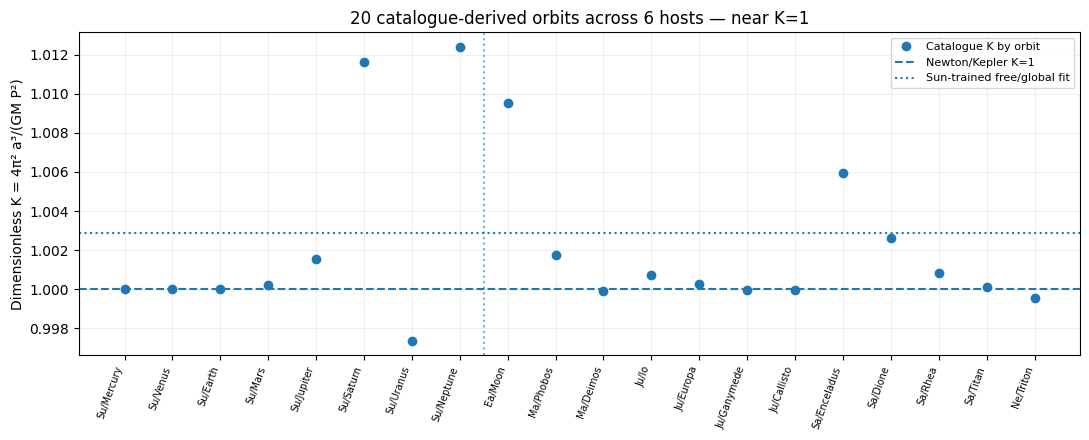

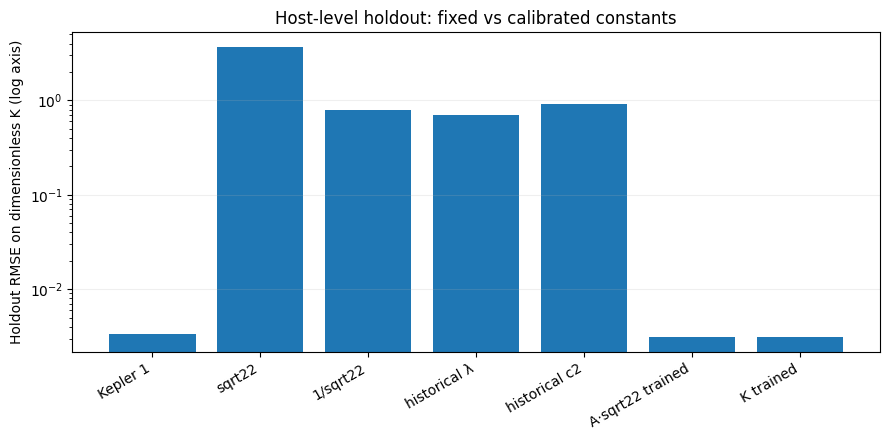

In [6]:
fig,ax=plt.subplots(figsize=(11,4.5))
ax.plot(np.arange(len(df)),K,'o',label='Catalogue K by orbit')
ax.axhline(1,ls='--',label='Newton/Kepler K=1')
ax.axhline(free_fit,ls=':',label='Sun-trained free/global fit')
ax.axvline(7.5,ls=':',alpha=0.6)
ax.set_xticks(np.arange(len(df)))
ax.set_xticklabels([f'{h[:2]}/{n}' for h,n in zip(df.host,df.body)],rotation=70,ha='right',fontsize=7)
ax.set_ylabel('Dimensionless K = 4π² a³/(GM P²)')
ax.set_title('20 catalogue-derived orbits across 6 hosts — near K=1')
ax.legend(fontsize=8);ax.grid(alpha=0.2)
fig.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,4.5))
key=['Newton_Kepler_K_eq_1','ROOT22_unscaled','inverse_ROOT22_unscaled','historical_lambda_unscaled','historical_c2_unscaled','ROOT22_times_calibrated_A','generic_constant_calibrated']
ax.bar(range(len(key)),[scores[z]['rmse'] for z in key]); ax.set_yscale('log')
ax.set_xticks(range(len(key))); ax.set_xticklabels(['Kepler 1','sqrt22','1/sqrt22','historical λ','historical c2','A·sqrt22 trained','K trained'],rotation=30,ha='right')
ax.set_ylabel('Holdout RMSE on dimensionless K (log axis)')
ax.set_title('Host-level holdout: fixed vs calibrated constants')
ax.grid(axis='y',alpha=0.2);fig.tight_layout();plt.show()

## Level 4 — Scientific verdict and operational gates

**Scientific conclusion:** the narrow literal root22 embeddings into the Kepler ratio are not supported by these catalogue-derived values. Allowing free multiplicative, divisive, or additive coefficients makes the occurrence of root22 **unidentifiable**: it is algebraically absorbed into a single generic scale. **This does not exclude all conceivable future laws involving $\sqrt{22}$**; no physical link from the G284 root-bearing dispersion to the orbital invariant was derived or tested.

**External validity caveats:** host groups all belong to our Solar System; published satellite elements/periods often share underlying dynamical models; mixed approximations and coarse published digits are not independent raw measurements. It is inappropriate to compute high-confidence significance from this table. No exoplanet catalogue, ALMA line data, or new GVH SI prediction is involved.

**Permitted next gate:** derive a dimensionless prediction from a *healthy, constraint-compatible* GVH branch **without fitting the target observable**, then test on an independent holdout and compare with GR/Einstein-æther. Also keep CHH conditional composition (addition/products/quotients) separate from a physical derivation.

In [7]:
report={
 'notebook':STEM,
 'category':'cross_system_catalogue_consistency_and_nonidentifiability_audit',
 'data_type':'frozen_published_orbital_parameters_not_independent_raw_astrometry',
 'source_date':'2026-11-18',
 'hypothesis':'Literal sqrt22 factors in a Kepler dimensionless orbital invariant; user-inspired auxiliary test, not derived from G284.',
 'historical':{'sqrt22':root,'lambda':lam_f,'c2':c2_f,'frozen_point_reduced_health_pass':False},
 'provenance':provenance,
 'sample':{'n':int(len(df)),'hosts':sorted(df.host.unique().tolist()),'train_host':['Sun'],'heldout_hosts':sorted(df.loc[hold,'host'].unique().tolist()),'n_train':int(train.sum()),'n_holdout':int(hold.sum())},
 'invariant':{'expression':'K=4*pi**2*a_km**3/(GM_host_km3_s2*(P_days*86400)**2)','K_min':float(K.min()),'K_max':float(K.max()),'K_mean':float(K.mean()),'K_training_mean':free_fit,'K_heldout_mean':float(K_hold.mean())},
 'fits':{'A_times_sqrt22':A_fit,'B_add_to_sqrt22':add_fit,'B_divided_by_sqrt22':div_fit,'generic_fit':free_fit},
 'model_predictions':models,'holdout_scores':scores,
 'source_urls':sources,
 'data_rows':df[['host','body','a_km','P_days','gm_host_km3_s2','source_id','source_url','partition','K_obs']].to_dict('records'),
 'checks':checks,'checks_passed':int(sum(checks.values())),'checks_total':int(len(checks)),
 'scientific_flags':{
  'historical_root22_algebra_exact':True,
  'cross_system_literal_sqrt22_supported_for_tested_K':False,
  'sqrt22_identifiable_after_free_scalar_adjustment':False,
  'new_GVH_physical_constant_discovered':False,
  'original_G284_frozen_branch_physically_healthy':False,
  'real_ephemeris_catalogue_consistency_test_performed':True,
  'raw_observation_independent_validation':False,
  'new_GVH_SI_prediction_tested':False,
  'all_possible_root22_physical_laws_excluded':False,
 },
 'verdict':'NO_EVIDENCE_OF_UNIVERSAL_ROOT22_IN_THIS_PREDEFINED_ORBITAL_TEST__FITTED_ROOT22_IS_ALGEBRAICALLY_REDUNDANT',
 'method_limits':['Pre-selected observable chosen for a falsifiable benchmark; no action-derived map G284 to orbital K.','All sampled orbits Solar System; not independent star systems.','Inputs are compiled fitted orbital elements, not raw independent measurements.','GM system vs primary GM and epoch/mean/sidereal reference conventions may differ; no formal error propagation.'],
}
check('all_numeric_checks_passed_before_export',all(checks.values()))
report['checks']=checks;report['checks_passed']=int(sum(checks.values()));report['checks_total']=int(len(checks))
outfile=OUT/(STEM+'_results.json')
outfile.write_text(json.dumps(report,indent=2,ensure_ascii=False,allow_nan=False)+'\n',encoding='utf-8')
print('Results JSON',outfile, 'checks',report['checks_passed'],'/',report['checks_total'])
print('VERDICT',report['verdict'])

Results JSON /mnt/data/GVH_CHH_Root22_Cross_System_Invariant_Universality_Gate_FAST_results.json checks 41 / 41
VERDICT NO_EVIDENCE_OF_UNIVERSAL_ROOT22_IN_THIS_PREDEFINED_ORBITAL_TEST__FITTED_ROOT22_IS_ALGEBRAICALLY_REDUNDANT
